In [2]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from dotenv import load_dotenv
import os

In [3]:
load_dotenv()

True

In [4]:
api_key=os.getenv("GROQ_API_KEY")

In [5]:
llm=ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=api_key
)

In [6]:
 class llmstate(TypedDict):
    question:str
    answer:str

In [7]:
def llmq(state :llmstate)->llmstate:
    question=state['question']
    prompt=f"answer the following question{question}"

    answer=llm.invoke(prompt).content
    state['answer']=answer
    return state


In [8]:
graph=StateGraph(llmstate)

graph.add_node("llmq",llmq)

graph.add_edge(START,"llmq")

graph.add_edge("llmq",END)

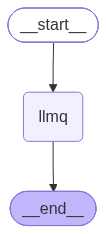

In [9]:
workflow=graph.compile()
workflow

In [10]:
intial_state={"question":"who is virat kohli"}
final_state=workflow.invoke(intial_state)
final_state

{'question': 'who is virat kohli',
 'answer': 'Virat Kohli is an Indian international cricketer widely regarded as one of the best contemporary batsmen. Born on 5\u202fNovember\u202f1988 in Delhi, he made his Test debut in 2011 and quickly became a mainstay of India’s batting lineup. Kohli captained the Indian national team in all formats from 2014 to 2022, leading India to a historic Test series win in Australia (2018–19) and a World Cup victory in 2011. Known for his aggressive style, consistency, and fitness, he has amassed over 12,000 runs in Tests and more than 12,000 in ODIs, with numerous centuries and a record for the fastest to 8,000 ODI runs. Off the field, he is a prominent brand ambassador and philanthropist.'}